# Parte Específica — EDA do Pump it Up

Projeto Final AVD 2026.2 — Grupo 6. Responsável: **Gustavo**.

Dataset: [Pump it Up: Data Mining the Water Table (DrivenData)](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/). Classe: `status_group` (`functional`, `functional needs repair`, `non functional`).

> **Sobre o uso de IA neste notebook:** as células de código marcadas com `# [IA]` foram geradas com apoio de IA para *tornar a análise possível* (cálculos, tabelas e gráficos). Toda interpretação, discussão e decisão de tratamento é autoral do grupo e fica nas células "Interpretação autoral".

## 0. Pergunta de pesquisa e público-alvo

**Pergunta (versão inicial):** *Can you predict which water pumps are faulty?*

**Público-alvo:** gestor público (ex.: Ministério da Água da Tanzânia).

> **[Interpretação autoral — preencher]**

## Configuração

In [1]:
# [IA] Claude Code – configuração (imports, caminhos, cores da classe e função para salvar figuras)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Sobe pastas até achar a raiz do repositório (onde está o requirements.txt),
# para o notebook funcionar não importa de onde o Jupyter foi aberto.
ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "parte_especifica"
OUT_DIR = ROOT / "out" / "parte_especifica"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Aparência (mude aqui se quiser) ---------------------------------------------
TEMA_ESCURO = False  # True = gráficos com fundo escuro, para quem lê no Jupyter escuro.
                     # Volte para False antes de gerar as figuras do relatório (PNG em fundo branco).
if TEMA_ESCURO:
    plt.style.use("dark_background")
    sns.set_theme(style="darkgrid", rc={"axes.facecolor": "#1f1f1f", "figure.facecolor": "#161616"})
else:
    sns.set_theme(style="whitegrid")

# Fontes maiores, para ler sem esforço
plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.dpi": 110,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Ordem e cores fixas da classe, para todos os gráficos da EDA lerem igual.
# Paleta Okabe-Ito, legível para pessoas com daltonismo (acessibilidade de cores, Aula 05).
# Pode trocar à vontade.
STATUS_ORDEM = ["functional", "functional needs repair", "non functional"]
STATUS_CORES = {
    "functional": "#0072B2",
    "functional needs repair": "#E69F00",
    "non functional": "#D55E00",
}


def salvar(fig, nome):
    """Salva a figura em out/parte_especifica/<nome>.png."""
    fig.savefig(OUT_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")


print("Raiz do projeto encontrada:", ROOT.name)

Raiz do projeto encontrada: projeto-avd-2026-2-pump-it-up-classificatorio


## Carga dos dados

In [2]:
# [IA] Claude Code – leitura do dataset bruto (df_raw nunca é alterado)
df_raw = pd.read_csv(DATA_DIR / "raw" / "pump_it_up_train.csv")
df = df_raw.copy()
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

59,400 linhas x 41 colunas


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,subvillage,region,region_code,district_code,lga,ward,population,public_meeting,recorded_by,scheme_management,scheme_name,permit,construction_year,extraction_type,extraction_type_group,extraction_type_class,management,management_group,payment,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Mnyusi B,Iringa,11,5,Ludewa,Mundindi,109,True,GeoData Consultants Ltd,VWC,Roman,False,1999,gravity,gravity,gravity,vwc,user-group,pay annually,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Nyamara,Mara,20,2,Serengeti,Natta,280,NaN,GeoData Consultants Ltd,Other,NaN,True,2010,gravity,gravity,gravity,wug,user-group,never pay,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Majengo,Manyara,21,4,Simanjiro,Ngorika,250,True,GeoData Consultants Ltd,VWC,Nyumba ya mungu pipe scheme,True,2009,gravity,gravity,gravity,vwc,user-group,pay per bucket,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mahakamani,Mtwara,90,63,Nanyumbu,Nanyumbu,58,True,GeoData Consultants Ltd,VWC,NaN,True,1986,submersible,submersible,submersible,vwc,user-group,never pay,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kyanyamisa,Kagera,18,1,Karagwe,Nyakasimbi,0,True,GeoData Consultants Ltd,NaN,NaN,True,0,gravity,gravity,gravity,other,other,never pay,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


### Valores distintos das colunas-chave

Lista cada valor com a contagem de linhas (`value_counts`), incluindo os faltantes (`NaN`). Só as colunas com poucos valores: as de muitos valores (`wpt_name`, `subvillage`, `funder`, `installer`, `scheme_name`, `ward`, `lga`) ficam de fora. O significado dos valores está em `docs/GLOSSARIO.md`.

In [3]:
# [IA] Claude Code – lista os valores distintos (com contagem) das colunas qualitativas-chave
COLS_CHAVE = [
    # alvo
    "status_group",
    # poucas categorias, já agrupadas
    "quantity", "management_group", "quality_group", "source_class",
    "extraction_type_class", "payment_type", "waterpoint_type_group", "basin",
    # com faltantes
    "public_meeting", "permit", "scheme_management",
]

for col in COLS_CHAVE:
    contagem = df[col].value_counts(dropna=False)   # dropna=False mostra também os faltantes (NaN)
    print(f"{col}: {df[col].nunique()} valores distintos")
    print(contagem.to_string())
    print()

status_group: 3 valores distintos
status_group
functional                 32259
non functional             22824
functional needs repair     4317

quantity: 5 valores distintos
quantity
enough          33186
insufficient    15129
dry              6246
seasonal         4050
unknown           789

management_group: 5 valores distintos
management_group
user-group    52490
commercial     3638
parastatal     1768
other           943
unknown         561

quality_group: 6 valores distintos
quality_group
good        50818
salty        5195
unknown      1876
milky         804
colored       490
fluoride      217

source_class: 3 valores distintos
source_class
groundwater    45794
surface        13328
unknown          278

extraction_type_class: 7 valores distintos
extraction_type_class
gravity         26780
handpump        16456
other            6430
submersible      6179
motorpump        2987
rope pump         451
wind-powered      117

payment_type: 7 valores distintos
payment_type
never pay  

## 1. Análise Estrutural

Tipos, dimensões, cardinalidade, duplicados, colunas constantes, colunas redundantes e consistência dos textos.

In [4]:
# [IA] Claude Code – visão geral de cada coluna (tipo, nº de valores únicos, nulos e um exemplo)
resumo = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "exemplo": df.iloc[0],
})
resumo.sort_values("n_unicos")

,tipo_pandas,n_unicos,n_nulos,pct_nulos,exemplo
recorded_by,str,1,0,0.00,GeoData Consultants Ltd
public_meeting,object,2,3334,5.61,True
permit,object,2,3056,5.14,False
source_class,str,3,0,0.00,groundwater
status_group,str,3,0,0.00,functional
quantity_group,str,5,0,0.00,enough
quantity,str,5,0,0.00,enough
management_group,str,5,0,0.00,user-group
quality_group,str,6,0,0.00,good
waterpoint_type_group,str,6,0,0.00,communal standpipe


In [5]:
# [IA] Claude Code – separação das colunas em grupos usados no resto do notebook
COL_ID = "id"
COL_ALVO = "status_group"

# Medidas quantitativas
COLS_NUM = ["amount_tsh", "gps_height", "longitude", "latitude",
            "num_private", "population", "construction_year"]
# Numéricas no arquivo, mas são códigos de localização (na prática, qualitativas)
COLS_CODIGO = ["region_code", "district_code"]
COLS_DATA = ["date_recorded"]
# Todo o resto (exceto id e alvo) é qualitativo
COLS_CAT = [c for c in df.columns
            if c not in COLS_NUM + COLS_CODIGO + COLS_DATA + [COL_ID, COL_ALVO]]

print(f"Quantitativas ({len(COLS_NUM)}): {COLS_NUM}")
print(f"Códigos numéricos ({len(COLS_CODIGO)}): {COLS_CODIGO}")
print(f"Data ({len(COLS_DATA)}): {COLS_DATA}")
print(f"Qualitativas ({len(COLS_CAT)}): {COLS_CAT}")

Quantitativas (7): ['amount_tsh', 'gps_height', 'longitude', 'latitude', 'num_private', 'population', 'construction_year']
Códigos numéricos (2): ['region_code', 'district_code']
Data (1): ['date_recorded']
Qualitativas (29): ['funder', 'installer', 'wpt_name', 'basin', 'subvillage', 'region', 'lga', 'ward', 'public_meeting', 'recorded_by', 'scheme_management', 'scheme_name', 'permit', 'extraction_type', 'extraction_type_group', 'extraction_type_class', 'management', 'management_group', 'payment', 'payment_type', 'water_quality', 'quality_group', 'quantity', 'quantity_group', 'source', 'source_type', 'source_class', 'waterpoint_type', 'waterpoint_type_group']


In [6]:
# [IA] Claude Code – linhas duplicadas, ids repetidos e colunas com um único valor
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("Linhas duplicadas (ignorando o id):", df.drop(columns=COL_ID).duplicated().sum())
print("Ids repetidos:", df[COL_ID].duplicated().sum())

constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Colunas com um único valor:", constantes)
for c in constantes:
    print(f"  {c}: {df[c].unique()}")

Linhas duplicadas (todas as colunas): 0


Linhas duplicadas (ignorando o id): 36
Ids repetidos: 0
Colunas com um único valor: ['recorded_by']
  recorded_by: <StringArray>
['GeoData Consultants Ltd']
Length: 1, dtype: str


### 1.1 Colunas redundantes

Várias colunas aparecem em "famílias" (ex.: `extraction_type`, `extraction_type_group`, `extraction_type_class`). A tabela abaixo verifica, para cada par, se a coluna mais geral é só um agrupamento da mais detalhada: cada categoria da detalhada cai sempre em **uma única** categoria da geral.

In [7]:
# [IA] Claude Code – verifica se as colunas "irmãs" são agrupamentos umas das outras
FAMILIAS = {
    "extraction_type": ["extraction_type", "extraction_type_group", "extraction_type_class"],
    "quantity": ["quantity", "quantity_group"],
    "payment": ["payment", "payment_type"],
    "water_quality": ["water_quality", "quality_group"],
    "source": ["source", "source_type", "source_class"],
    "waterpoint_type": ["waterpoint_type", "waterpoint_type_group"],
    "management": ["management", "management_group"],
}

linhas = []
for familia, cols in FAMILIAS.items():
    for detalhada, geral in zip(cols[:-1], cols[1:]):
        # maior nº de categorias "gerais" associadas a uma mesma categoria "detalhada"
        max_gerais = df.groupby(detalhada, dropna=False)[geral].nunique(dropna=False).max()
        linhas.append({
            "familia": familia,
            "detalhada": detalhada,
            "geral": geral,
            "n_cat_detalhada": df[detalhada].nunique(),
            "n_cat_geral": df[geral].nunique(),
            "geral_e_agrupamento_da_detalhada": max_gerais == 1,
        })
pd.DataFrame(linhas)

,familia,detalhada,geral,n_cat_detalhada,n_cat_geral,geral_e_agrupamento_da_detalhada
0,extraction_type,extraction_type,extraction_type_group,18,13,True
1,extraction_type,extraction_type_group,extraction_type_class,13,7,True
2,quantity,quantity,quantity_group,5,5,True
3,payment,payment,payment_type,7,7,True
4,water_quality,water_quality,quality_group,8,6,True
5,source,source,source_type,10,7,True
6,source,source_type,source_class,7,3,True
7,waterpoint_type,waterpoint_type,waterpoint_type_group,7,6,True
8,management,management,management_group,12,5,True


In [8]:
# [IA] Claude Code – exemplos lado a lado: como as categorias se correspondem
display(pd.crosstab(df["quantity"], df["quantity_group"]))
display(pd.crosstab(df["payment"], df["payment_type"]))

quantity_group,dry,enough,insufficient,seasonal,unknown
quantity,,,,,
dry,6246,0,0,0,0
enough,0,33186,0,0,0
insufficient,0,0,15129,0,0
seasonal,0,0,0,4050,0
unknown,0,0,0,0,789


payment_type,annually,monthly,never pay,on failure,other,per bucket,unknown
payment,,,,,,,
never pay,0,0,25348,0,0,0,0
other,0,0,0,0,1054,0,0
pay annually,3642,0,0,0,0,0,0
pay monthly,0,8300,0,0,0,0,0
pay per bucket,0,0,0,0,0,8985,0
pay when scheme fails,0,0,0,3914,0,0,0
unknown,0,0,0,0,0,0,8157


### 1.2 Consistência entre `region` e `region_code`

In [9]:
# [IA] Claude Code – quantos códigos existem por região e quantas regiões por código
codigos_por_regiao = df.groupby("region")["region_code"].unique().apply(sorted)
print("Regiões com mais de um region_code:")
display(codigos_por_regiao[codigos_por_regiao.apply(len) > 1])

regioes_por_codigo = df.groupby("region_code")["region"].unique().apply(sorted)
print("region_code com mais de uma região:")
display(regioes_por_codigo[regioes_por_codigo.apply(len) > 1])

Regiões com mais de um region_code:


region
Arusha            [2, 24]
Lindi         [8, 18, 80]
Mtwara        [9, 90, 99]
Mwanza           [17, 19]
Pwani         [6, 40, 60]
Shinyanga    [11, 14, 17]
Tanga              [4, 5]
Name: region_code, dtype: object

region_code com mais de uma região:


region_code
5       [Morogoro, Tanga]
11    [Iringa, Shinyanga]
14    [Shinyanga, Tabora]
17    [Mwanza, Shinyanga]
18        [Kagera, Lindi]
Name: region, dtype: object

### 1.3 Alta cardinalidade e grafias diferentes do mesmo nome

In [10]:
# [IA] Claude Code – nº de categorias antes e depois de padronizar maiúsculas/espaços
linhas = []
for col in ["funder", "installer", "wpt_name", "subvillage", "scheme_name", "ward", "lga"]:
    s = df[col].dropna().astype(str)
    linhas.append({
        "coluna": col,
        "n_unicos": s.nunique(),
        "n_unicos_minusculo_sem_espacos": s.str.strip().str.lower().nunique(),
        "top_5": s.value_counts().head(5).to_dict(),
    })
pd.DataFrame(linhas)

,coluna,n_unicos,n_unicos_minusculo_sem_espacos,top_5
0,funder,1896,1896,"{'Government Of Tanzania': 9084, 'Danida': 311..."
1,installer,2145,1935,"{'DWE': 17402, 'Government': 1825, 'RWE': 1206..."
2,wpt_name,37399,37399,"{'none': 3563, 'Shuleni': 1748, 'Zahanati': 83..."
3,subvillage,19287,19287,"{'Madukani': 508, 'Shuleni': 506, 'Majengo': 5..."
4,scheme_name,2695,2576,"{'K': 682, 'Borehole': 546, 'Chalinze wate': 4..."
5,ward,2092,2092,"{'Igosi': 307, 'Imalinyi': 252, 'Siha Kati': 2..."
6,lga,125,125,"{'Njombe': 2503, 'Arusha Rural': 1252, 'Moshi ..."


> **[Interpretação autoral — preencher]**

## 2. Qualidade dos dados e mecanismo de ausência

Faltantes explícitos (`NaN`), zeros e códigos que podem esconder faltantes, e como a ausência se distribui (entre colunas, por região, por ano de registro e por classe). Essa é a base para discutir o mecanismo (MCAR, MAR ou MNAR, Aula 09) antes de decidir qualquer tratamento.

**Nada é alterado em `df` nesta seção.**

In [11]:
# [IA] Claude Code – faltantes explícitos (NaN)
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pd.DataFrame({"n_nulos": nulos, "pct": (nulos / len(df) * 100).round(2)})

,n_nulos,pct
scheme_name,28810,48.50
scheme_management,3878,6.53
installer,3655,6.15
funder,3637,6.12
public_meeting,3334,5.61
permit,3056,5.14
subvillage,371,0.62
wpt_name,2,0.00


In [12]:
# [IA] Claude Code – zeros, valores negativos e códigos que podem esconder faltantes
suspeitos = {
    "population == 0": df["population"] == 0,
    "construction_year == 0": df["construction_year"] == 0,
    "gps_height == 0": df["gps_height"] == 0,
    "gps_height < 0": df["gps_height"] < 0,
    "longitude == 0": df["longitude"] == 0,
    # a Tanzânia inteira fica no hemisfério sul, então latitude ~0 é suspeita
    "latitude > -0.001": df["latitude"] > -0.001,
    "amount_tsh == 0": df["amount_tsh"] == 0,
    "num_private == 0": df["num_private"] == 0,
    "funder in {'0', '-'}": df["funder"].isin(["0", "-"]),
    "installer in {'0', '-'}": df["installer"].isin(["0", "-"]),
}
pd.DataFrame({
    "n": {k: int(v.sum()) for k, v in suspeitos.items()},
    "pct": {k: round(v.mean() * 100, 2) for k, v in suspeitos.items()},
})

,n,pct
population == 0,21381,35.99
construction_year == 0,20709,34.86
gps_height == 0,20438,34.41
gps_height < 0,1496,2.52
longitude == 0,1812,3.05
latitude > -0.001,1812,3.05
amount_tsh == 0,41639,70.10
num_private == 0,58643,98.73
"funder in {'0', '-'}",777,1.31
"installer in {'0', '-'}",780,1.31


In [13]:
# [IA] Claude Code – verificação: longitude == 0 e latitude ~0 acontecem nas mesmas linhas?
pd.crosstab(df["longitude"] == 0, df["latitude"] > -0.001,
            rownames=["longitude == 0"], colnames=["latitude > -0.001"])

latitude > -0.001,False,True
longitude == 0,,
False,57588,0
True,0,1812


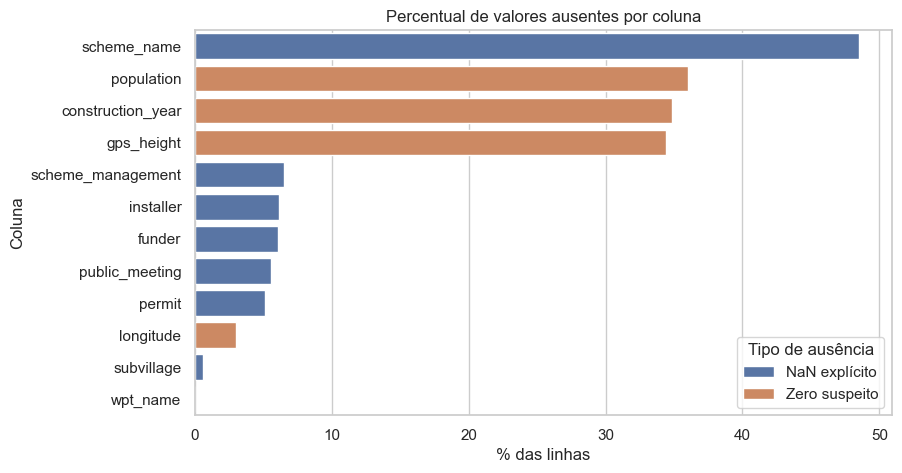

In [14]:
# [IA] Claude Code – gráfico: % de ausência por coluna (NaN explícito e zero suspeito)
pct_nan = (df.isna().mean() * 100)[lambda s: s > 0]
pct_zero = pd.Series({c: (df[c] == 0).mean() * 100
                      for c in ["population", "construction_year", "gps_height", "longitude"]})
graf = pd.concat([
    pd.DataFrame({"coluna": pct_nan.index, "pct": pct_nan.values, "tipo": "NaN explícito"}),
    pd.DataFrame({"coluna": pct_zero.index, "pct": pct_zero.values, "tipo": "Zero suspeito"}),
]).sort_values("pct", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=graf, y="coluna", x="pct", hue="tipo", dodge=False, ax=ax)
ax.set_title("Percentual de valores ausentes por coluna")
ax.set_xlabel("% das linhas")
ax.set_ylabel("Coluna")
ax.legend(title="Tipo de ausência")
salvar(fig, "02_ausencia_por_coluna")
plt.show()

### 2.1 Indicadores de ausência

Uma coluna 0/1 por variável (1 = ausente, contando `NaN` e os códigos suspeitos acima). Usada só para estudar o mecanismo.

In [15]:
# [IA] Claude Code – indicadores de ausência (1 = ausente)
ausente = pd.DataFrame({
    "population": df["population"] == 0,
    "construction_year": df["construction_year"] == 0,
    "gps_height": df["gps_height"] == 0,
    "longitude": df["longitude"] == 0,
    "scheme_name": df["scheme_name"].isna(),
    "scheme_management": df["scheme_management"].isna(),
    "installer": df["installer"].isna() | df["installer"].isin(["0", "-"]),
    "funder": df["funder"].isna() | df["funder"].isin(["0", "-"]),
    "public_meeting": df["public_meeting"].isna(),
    "permit": df["permit"].isna(),
}).astype(int)
ausente.mean().mul(100).round(2).sort_values(ascending=False)

scheme_name          48.50
population           35.99
construction_year    34.86
gps_height           34.41
installer             7.47
funder                7.43
scheme_management     6.53
public_meeting        5.61
permit                5.14
longitude             3.05
dtype: float64

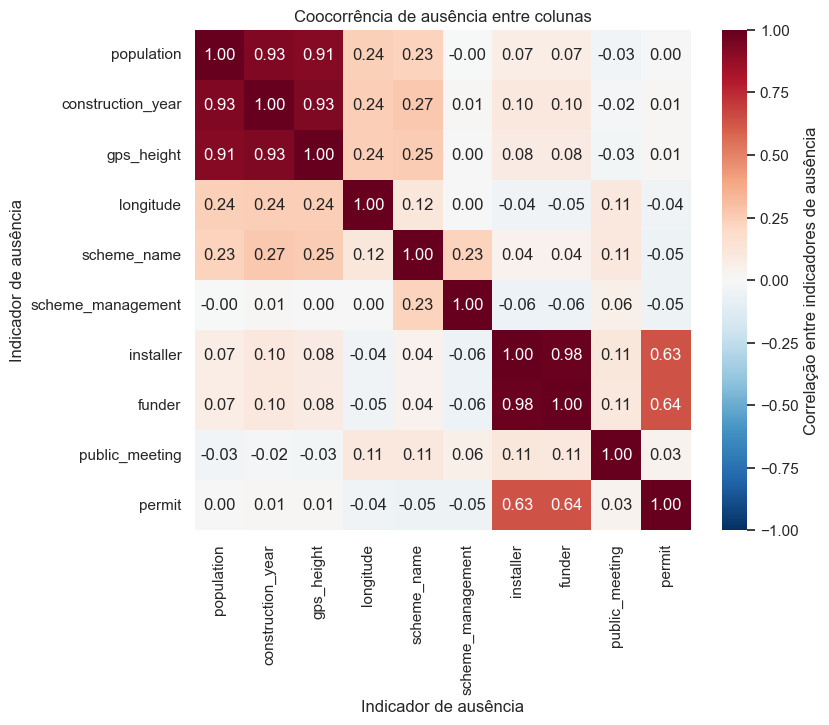

In [16]:
# [IA] Claude Code – gráfico: a ausência de uma coluna acompanha a de outra? (correlação entre os indicadores)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(ausente.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlação entre indicadores de ausência"}, ax=ax)
ax.set_title("Coocorrência de ausência entre colunas")
ax.set_xlabel("Indicador de ausência")
ax.set_ylabel("Indicador de ausência")
salvar(fig, "02_coocorrencia_ausencia")
plt.show()

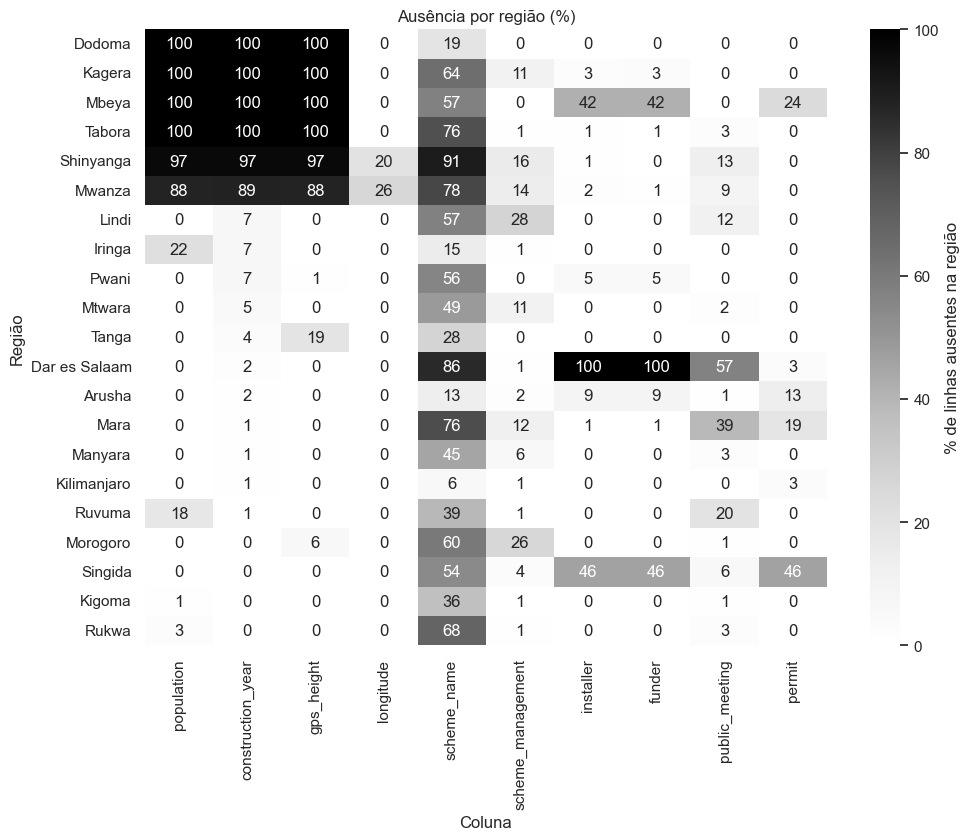

In [17]:
# [IA] Claude Code – gráfico: % de ausência de cada coluna dentro de cada região
por_regiao = ausente.groupby(df["region"]).mean().mul(100)
por_regiao = por_regiao.sort_values("construction_year", ascending=False)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(por_regiao, annot=True, fmt=".0f", cmap="Greys",
            cbar_kws={"label": "% de linhas ausentes na região"}, ax=ax)
ax.set_title("Ausência por região (%)")
ax.set_xlabel("Coluna")
ax.set_ylabel("Região")
salvar(fig, "02_ausencia_por_regiao")
plt.show()

In [18]:
# [IA] Claude Code – % de ausência por ano de registro (date_recorded)
ano_registro = pd.to_datetime(df["date_recorded"]).dt.year
display(ano_registro.value_counts().sort_index().rename("n_linhas").to_frame().T)
ausente.groupby(ano_registro).mean().mul(100).round(1)

date_recorded,2002,2004,2011,2012,2013
n_linhas,1,30,28674,6424,24271


,population,construction_year,gps_height,longitude,scheme_name,scheme_management,installer,funder,public_meeting,permit
date_recorded,,,,,,,,,,
2002,100.0,100.0,100.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0
2004,36.7,43.3,36.7,0.0,63.3,13.3,6.7,6.7,20.0,3.3
2011,48.3,46.5,46.8,2.0,47.5,6.3,7.8,7.8,1.2,3.9
2012,79.8,80.0,79.8,7.1,82.4,11.5,0.7,0.6,12.6,2.6
2013,9.9,9.1,7.7,3.3,40.7,5.5,8.8,8.8,8.9,7.3


In [19]:
# [IA] Claude Code – a ausência está associada à classe? (% de ausência dentro de cada status)
display(ausente.groupby(df[COL_ALVO]).mean().mul(100).round(1).reindex(STATUS_ORDEM))

# e o contrário: distribuição da classe entre linhas com e sem construction_year
pd.crosstab(ausente["construction_year"].map({0: "informado", 1: "ausente (0)"}),
            df[COL_ALVO], normalize="index").mul(100).round(1)[STATUS_ORDEM]

,population,construction_year,gps_height,longitude,scheme_name,scheme_management,installer,funder,public_meeting,permit
status_group,,,,,,,,,,
functional,34.9,32.7,32.5,2.7,46.2,5.8,7.6,7.5,5.2,5.2
functional needs repair,41.1,41.4,40.8,8.9,47.1,5.2,10.3,10.2,3.6,6.9
non functional,36.5,36.7,36.0,2.4,52.0,7.8,6.8,6.8,6.6,4.7


status_group,functional,functional needs repair,non functional
construction_year,,,
ausente (0),51.0,8.6,40.4
informado,56.1,6.5,37.4


### Mecanismo de ausência e tratamento proposto

> **[Interpretação autoral — preencher]**

## 3. Análise Distribucional

Distribuição da classe, das variáveis quantitativas e das qualitativas.

Nos gráficos das quantitativas, os zeros suspeitos da seção 2 são **escondidos apenas para a visualização** (cópia `viz`), para não deformar o eixo. `df` continua intacto.

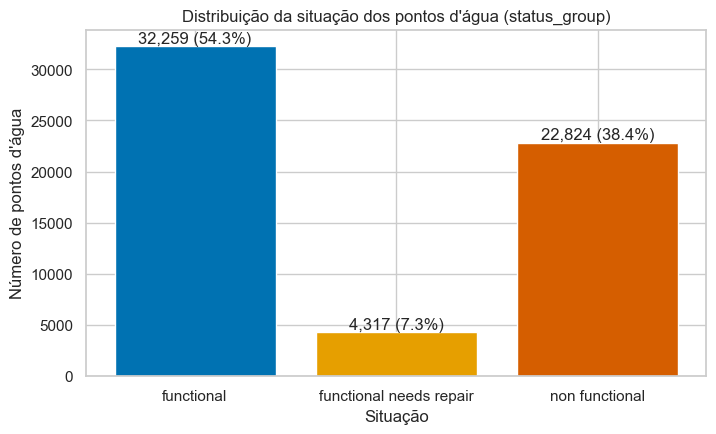

In [20]:
# [IA] Claude Code – gráfico: distribuição da classe
contagem = df[COL_ALVO].value_counts().reindex(STATUS_ORDEM)

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(contagem.index, contagem.values, color=[STATUS_CORES[s] for s in contagem.index])
ax.bar_label(barras, labels=[f"{v:,} ({v / len(df):.1%})" for v in contagem.values])
ax.set_title("Distribuição da situação dos pontos d'água (status_group)")
ax.set_xlabel("Situação")
ax.set_ylabel("Número de pontos d'água")
salvar(fig, "03_distribuicao_classe")
plt.show()

In [21]:
# [IA] Claude Code – cópia só para visualização: zeros suspeitos viram NaN
viz = df[COLS_NUM].copy()
for c in ["population", "construction_year", "gps_height"]:
    viz.loc[viz[c] == 0, c] = np.nan
viz.loc[df["longitude"] == 0, ["longitude", "latitude"]] = np.nan

estat = viz.describe().T
estat["assimetria"] = viz.skew()
estat["n_ausentes_na_viz"] = viz.isna().sum()
estat.round(2)

,count,mean,std,min,25%,50%,75%,max,assimetria,n_ausentes_na_viz
amount_tsh,59400.0,317.65,2997.57,0.00,0.00,0.00,20.00,350000.00,57.81,0
gps_height,38962.0,1018.86,612.57,-90.00,393.00,1167.00,1498.00,2770.00,-0.20,20438
longitude,57588.0,35.15,2.61,29.61,33.29,35.01,37.23,40.35,-0.13,1812
latitude,57588.0,-5.89,2.81,-11.65,-8.64,-5.17,-3.37,-1.00,-0.25,1812
num_private,59400.0,0.47,12.24,0.00,0.00,0.00,0.00,1776.00,91.93,0
population,38019.0,281.09,564.69,1.00,40.00,150.00,324.00,30500.00,10.99,21381
construction_year,38691.0,1996.81,12.47,1960.00,1987.00,2000.00,2008.00,2013.00,-0.73,20709


In [ ]:
# [IA] Claude Code – gráfico: histogramas das quantitativas (duas figuras, para ficarem maiores)
COLS_LOG = ["amount_tsh", "population", "num_private"]  # muito assimétricas: só valores > 0, eixo em log


def histogramas(colunas, nome, parte):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, col in zip(axes.flat, colunas):
        dados = viz[col].dropna()
        usar_log = col in COLS_LOG
        if usar_log:
            dados = dados[dados > 0]
        sns.histplot(dados, bins=40, log_scale=usar_log, ax=ax, color="#4C72B0")
        ax.set_title(col + (" (> 0, eixo log)" if usar_log else ""))
        ax.set_xlabel(col)
        ax.set_ylabel("Frequência")
    for ax in axes.flat[len(colunas):]:
        ax.axis("off")
    fig.suptitle(f"Distribuição das variáveis quantitativas, zeros suspeitos ocultos ({parte} de 2)", fontsize=15)
    fig.tight_layout()
    salvar(fig, nome)
    plt.show()


histogramas(COLS_NUM[:4], "03_histogramas_quantitativas_1", 1)
histogramas(COLS_NUM[4:], "03_histogramas_quantitativas_2", 2)

In [ ]:
# [IA] Claude Code – gráfico: frequência das qualitativas de baixa cardinalidade (até 30 categorias), 6 por figura
cats_baixa = [c for c in COLS_CAT + COLS_CODIGO if df[c].nunique() <= 30]
print(len(cats_baixa), "colunas:", cats_baixa)

POR_FIGURA = 6
n_partes = int(np.ceil(len(cats_baixa) / POR_FIGURA))
for parte, inicio in enumerate(range(0, len(cats_baixa), POR_FIGURA), start=1):
    grupo = cats_baixa[inicio:inicio + POR_FIGURA]
    fig, axes = plt.subplots(2, 3, figsize=(20, 11))
    for ax, col in zip(axes.flat, grupo):
        valores = df[col].astype("string").fillna("(ausente)")
        ordem = valores.value_counts().index
        sns.countplot(y=valores, order=ordem, ax=ax, color="#4C72B0")
        ax.set_title(col)
        ax.set_xlabel("Número de pontos d'água")
        ax.set_ylabel("")
    for ax in axes.flat[len(grupo):]:
        ax.axis("off")
    fig.suptitle(f"Frequência das variáveis qualitativas, até 30 categorias ({parte} de {n_partes})", fontsize=15)
    fig.tight_layout()
    salvar(fig, f"03_frequencias_qualitativas_{parte}")
    plt.show()

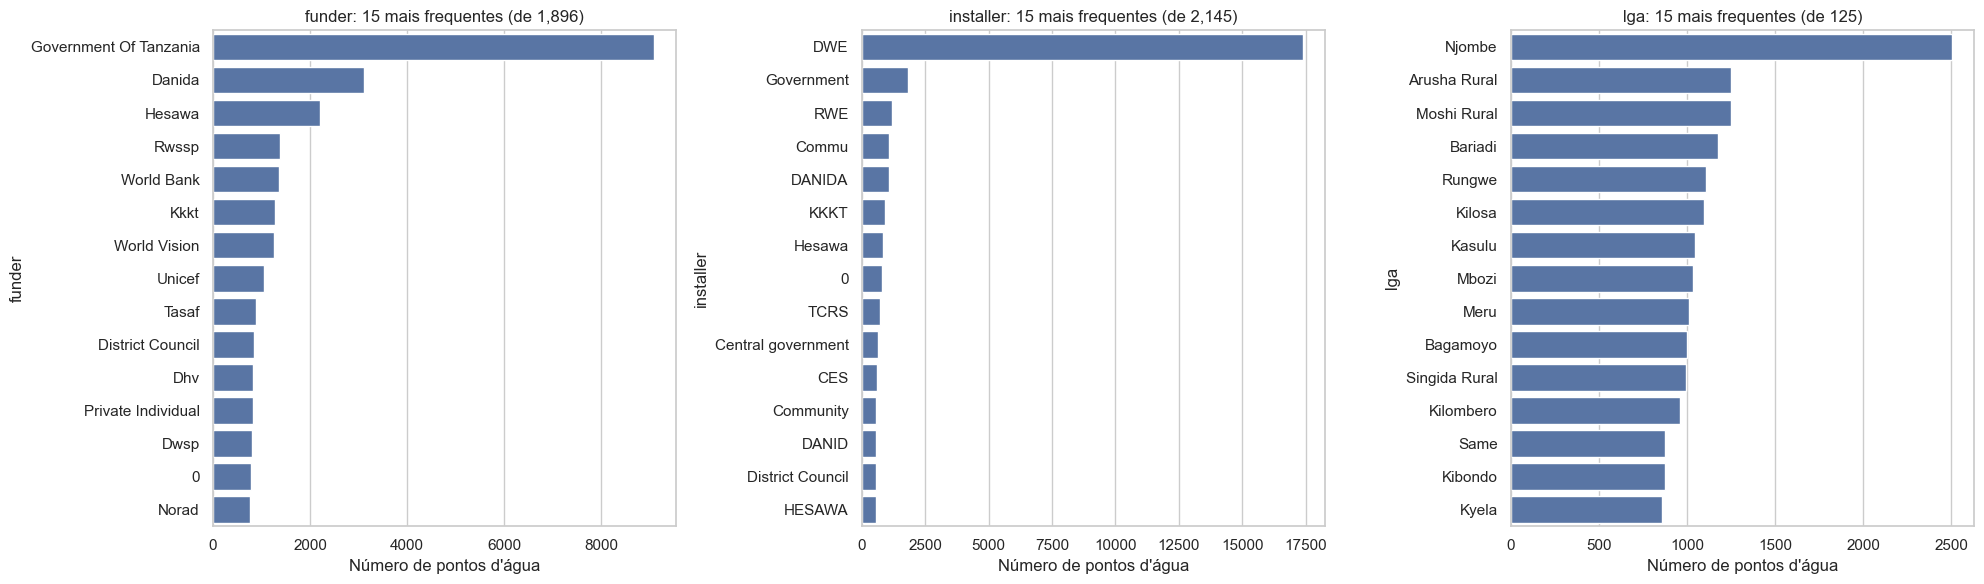

In [24]:
# [IA] Claude Code – gráfico: as 15 categorias mais frequentes das colunas de alta cardinalidade
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, col in zip(axes, ["funder", "installer", "lga"]):
    top = df[col].value_counts().head(15)
    sns.barplot(x=top.values, y=top.index, ax=ax, color="#4C72B0")
    ax.set_title(f"{col}: 15 mais frequentes (de {df[col].nunique():,})")
    ax.set_xlabel("Número de pontos d'água")
    ax.set_ylabel(col)
fig.tight_layout()
salvar(fig, "03_top_alta_cardinalidade")
plt.show()

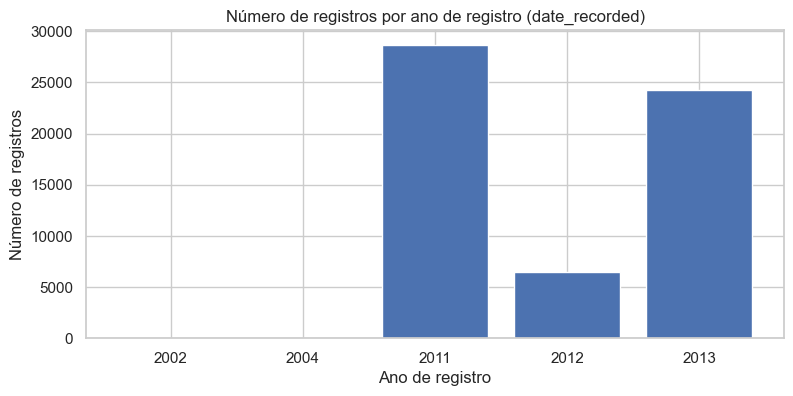

In [25]:
# [IA] Claude Code – gráfico: registros por ano (date_recorded)
ano_registro = pd.to_datetime(df["date_recorded"]).dt.year
contagem_ano = ano_registro.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(contagem_ano.index.astype(str), contagem_ano.values, color="#4C72B0")
ax.set_title("Número de registros por ano de registro (date_recorded)")
ax.set_xlabel("Ano de registro")
ax.set_ylabel("Número de registros")
salvar(fig, "03_registros_por_ano")
plt.show()

> **[Interpretação autoral — preencher]**

## 4. Análise Relacional (com `status_group`)

Relações entre as quantitativas, de cada variável com a classe e uma visão multivariada. Continua usando a cópia `viz` (zeros suspeitos ocultos) para as quantitativas.

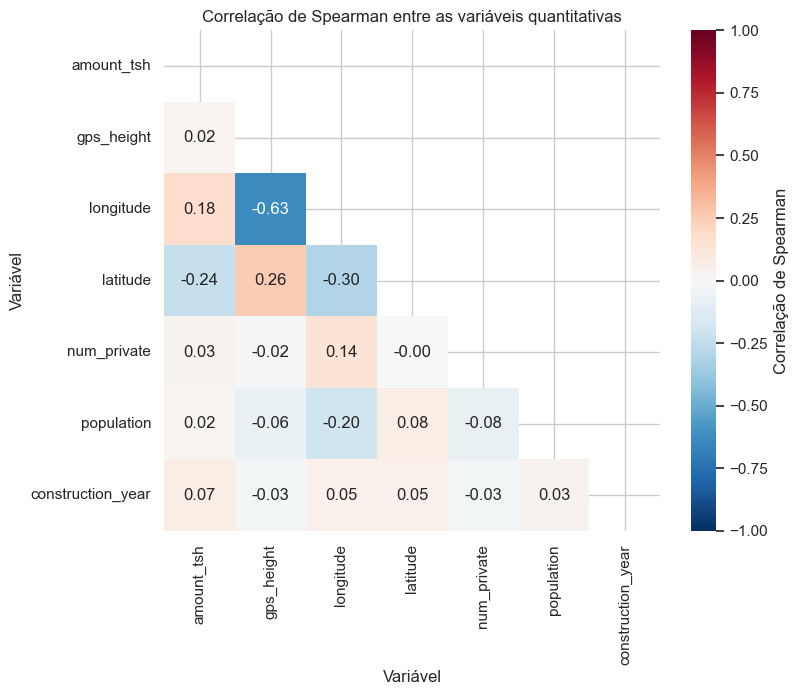

In [26]:
# [IA] Claude Code – gráfico: correlação de Spearman entre as quantitativas (pares com valores válidos)
corr = viz.corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlação de Spearman"}, ax=ax)
ax.set_title("Correlação de Spearman entre as variáveis quantitativas")
ax.set_xlabel("Variável")
ax.set_ylabel("Variável")
salvar(fig, "04_spearman_quantitativas")
plt.show()

In [27]:
# [IA] Claude Code – variável derivada (Aula 26, feature creation): idade do ponto d'água no registro
viz["idade_no_registro"] = pd.to_datetime(df["date_recorded"]).dt.year - viz["construction_year"]
print("Idades negativas (construção depois do registro):", (viz["idade_no_registro"] < 0).sum())
viz["idade_no_registro"].describe().round(1)

Idades negativas (construção depois do registro): 9


count    38691.0
mean        15.4
std         12.5
min         -7.0
25%          5.0
50%         13.0
75%         25.0
max         53.0
Name: idade_no_registro, dtype: float64

In [ ]:
# [IA] Claude Code – gráfico: cada quantitativa por classe (boxplot), duas figuras
cols_box = ["amount_tsh", "gps_height", "population", "construction_year",
            "idade_no_registro", "longitude", "latitude"]
dados_box = viz[cols_box].assign(status=df[COL_ALVO])


def boxplots_por_classe(colunas, nome, parte):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, col in zip(axes.flat, colunas):
        d = dados_box[[col, "status"]].dropna()
        usar_log = col in COLS_LOG
        if usar_log:
            d = d[d[col] > 0]
        sns.boxplot(data=d, x="status", y=col, hue="status", order=STATUS_ORDEM,
                    palette=STATUS_CORES, legend=False, ax=ax)
        if usar_log:
            ax.set_yscale("log")
        ax.set_title(col + (" (> 0, eixo log)" if usar_log else ""))
        ax.set_xlabel("Situação")
        ax.set_ylabel(col)
        ax.tick_params(axis="x", labelrotation=10)
    for ax in axes.flat[len(colunas):]:
        ax.axis("off")
    fig.suptitle(f"Variáveis quantitativas por situação do ponto d'água ({parte} de 2)", fontsize=15)
    fig.tight_layout()
    salvar(fig, nome)
    plt.show()


boxplots_por_classe(cols_box[:4], "04_quantitativas_por_classe_1", 1)
boxplots_por_classe(cols_box[4:], "04_quantitativas_por_classe_2", 2)

In [29]:
# [IA] Claude Code – função: proporção de cada status dentro das categorias de uma coluna
def proporcao_status(coluna):
    """Tabela com o % de cada status por categoria (linhas somam 100) e o n de cada categoria."""
    valores = df[coluna].astype("string").fillna("(ausente)")
    tabela = pd.crosstab(valores, df[COL_ALVO], normalize="index").mul(100)[STATUS_ORDEM]
    tabela["n"] = valores.value_counts()
    return tabela.sort_values("n", ascending=False)


proporcao_status("quantity").round(1)

status_group,functional,functional needs repair,non functional,n
quantity,,,,
enough,65.2,7.2,27.5,33186
insufficient,52.3,9.6,38.1,15129
dry,2.5,0.6,96.9,6246
seasonal,57.4,10.3,32.3,4050
unknown,27.0,1.8,71.2,789


In [ ]:
# [IA] Claude Code – gráfico: barras 100% empilhadas do status por categoria (versões agregadas das famílias), 6 por figura
cols_rel = ["quantity", "extraction_type_class", "waterpoint_type_group", "payment_type",
            "quality_group", "source_type", "management_group", "basin",
            "scheme_management", "public_meeting", "permit", "source_class"]

POR_FIGURA = 6
n_partes = int(np.ceil(len(cols_rel) / POR_FIGURA))
for parte, inicio in enumerate(range(0, len(cols_rel), POR_FIGURA), start=1):
    grupo = cols_rel[inicio:inicio + POR_FIGURA]
    fig, axes = plt.subplots(2, 3, figsize=(21, 11))
    for ax, col in zip(axes.flat, grupo):
        tabela = proporcao_status(col)
        tabela[STATUS_ORDEM].iloc[::-1].plot.barh(
            stacked=True, ax=ax, color=[STATUS_CORES[s] for s in STATUS_ORDEM], width=0.8, legend=False)
        ax.set_yticklabels([f"{i} (n={n:,})" for i, n in tabela["n"].iloc[::-1].items()])
        ax.set_title(col)
        ax.set_xlabel("% dos pontos d'água da categoria")
        ax.set_ylabel("")
        ax.set_xlim(0, 100)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Situação", loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.01))
    fig.suptitle(f"Situação do ponto d'água por categoria ({parte} de {n_partes})", fontsize=15, y=1.04)
    fig.tight_layout()
    salvar(fig, f"04_status_por_categoria_{parte}")
    plt.show()

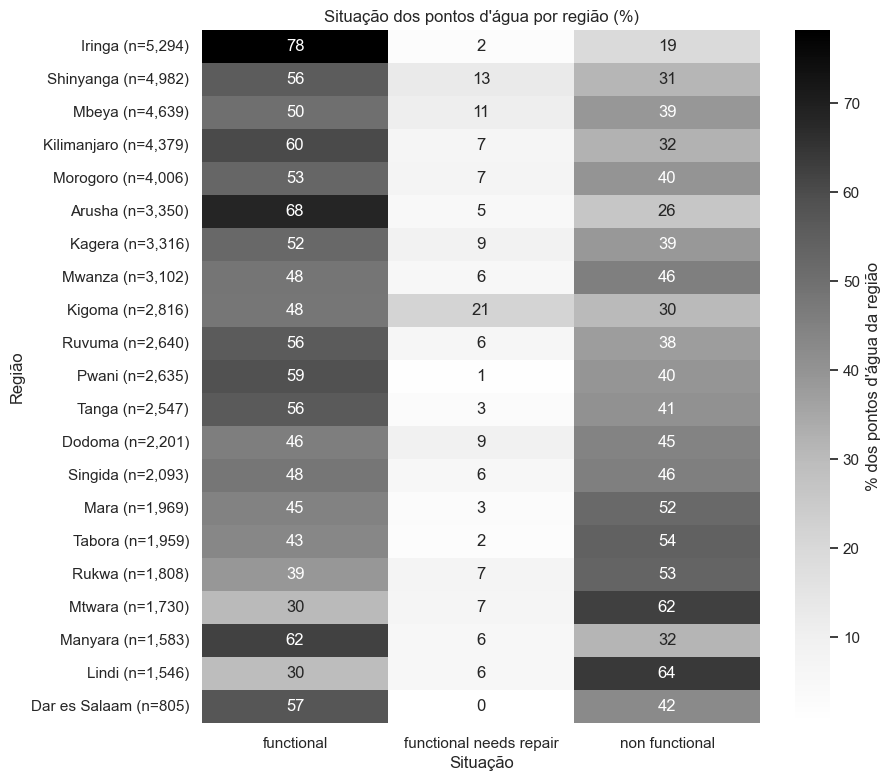

In [31]:
# [IA] Claude Code – gráfico: % de cada status por região
tabela_regiao = proporcao_status("region")

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(tabela_regiao[STATUS_ORDEM], annot=True, fmt=".0f", cmap="Greys",
            cbar_kws={"label": "% dos pontos d'água da região"}, ax=ax)
ax.set_yticklabels([f"{r} (n={n:,})" for r, n in tabela_regiao["n"].items()], rotation=0)
ax.set_title("Situação dos pontos d'água por região (%)")
ax.set_xlabel("Situação")
ax.set_ylabel("Região")
salvar(fig, "04_status_por_regiao")
plt.show()

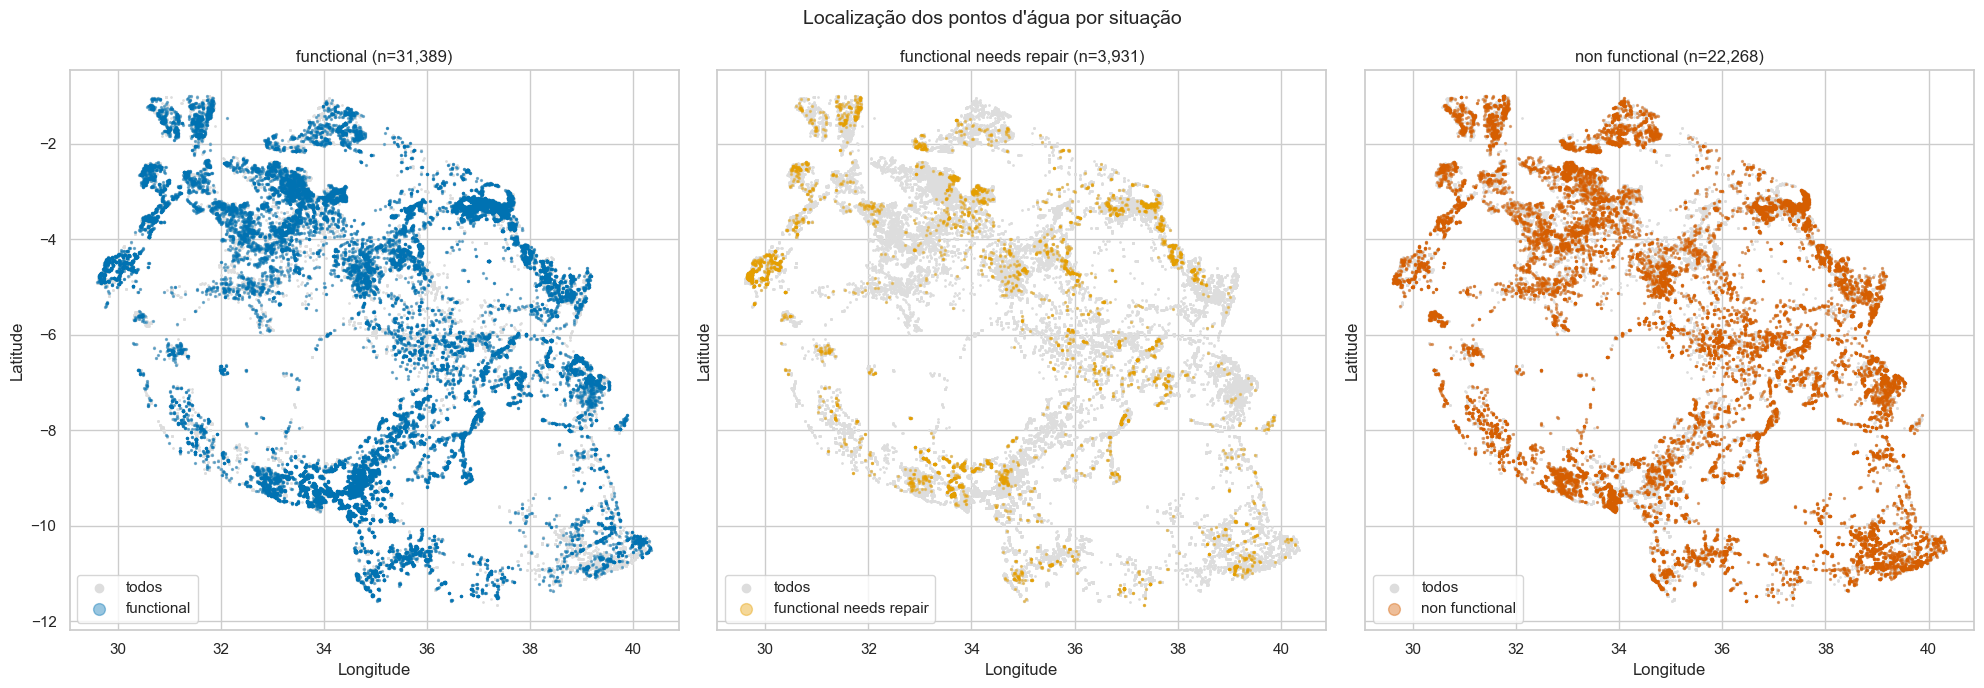

In [32]:
# [IA] Claude Code – gráfico: localização dos pontos d'água por status (coordenadas válidas)
geo = viz[["longitude", "latitude"]].assign(status=df[COL_ALVO]).dropna()

fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharex=True, sharey=True)
for ax, status in zip(axes, STATUS_ORDEM):
    ax.scatter(geo["longitude"], geo["latitude"], s=1, color="#DDDDDD", label="todos")
    sub = geo[geo["status"] == status]
    ax.scatter(sub["longitude"], sub["latitude"], s=2, alpha=0.4,
               color=STATUS_CORES[status], label=status)
    ax.set_title(f"{status} (n={len(sub):,})")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="lower left", markerscale=6)
fig.suptitle("Localização dos pontos d'água por situação", fontsize=14)
fig.tight_layout()
salvar(fig, "04_mapa_por_status")
plt.show()

### 4.1 Visão multivariada

Função para cruzar **duas** variáveis qualitativas e ver o % de um status em cada combinação. Abaixo, um exemplo; troque as colunas e o status para explorar outras combinações.

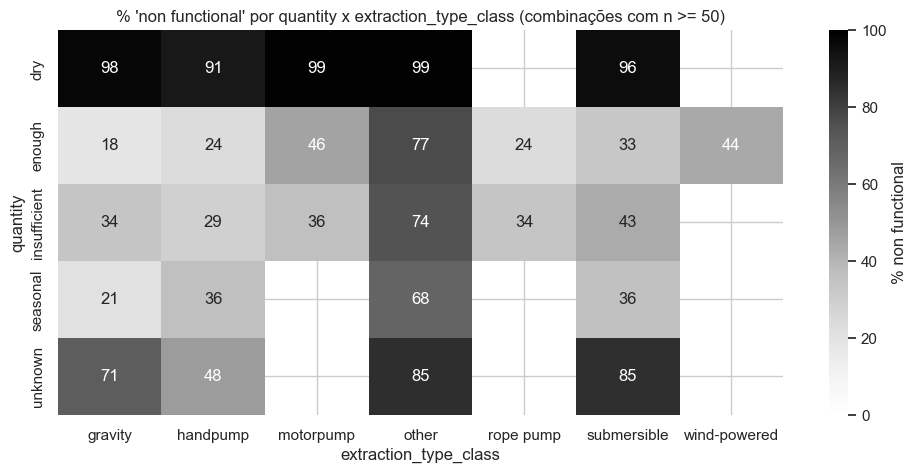

In [33]:
# [IA] Claude Code – função: % de um status em cada combinação de duas colunas qualitativas
def taxa_status(linha, coluna, status="non functional", n_min=50):
    """Heatmap do % de `status` em cada combinação (linha x coluna). Combinações com menos de n_min linhas ficam em branco."""
    grupos = df.groupby([linha, coluna])[COL_ALVO]
    taxa = grupos.apply(lambda s: (s == status).mean() * 100).unstack()
    n = grupos.size().unstack()
    taxa = taxa.where(n >= n_min)

    fig, ax = plt.subplots(figsize=(1.1 * taxa.shape[1] + 4, 0.5 * taxa.shape[0] + 2.5))
    sns.heatmap(taxa, annot=True, fmt=".0f", cmap="Greys", vmin=0, vmax=100,
                cbar_kws={"label": f"% {status}"}, ax=ax)
    ax.set_title(f"% '{status}' por {linha} x {coluna} (combinações com n >= {n_min})")
    ax.set_xlabel(coluna)
    ax.set_ylabel(linha)
    return fig, ax


fig, ax = taxa_status("quantity", "extraction_type_class")
salvar(fig, "04_multivariada_quantity_extraction")
plt.show()

> **[Interpretação autoral — preencher]**

## 5. Outliers

Identificação pelo critério do IQR (Aula 09), calculado sobre os valores válidos (cópia `viz`). Também listamos os maiores valores e casos impossíveis.

In [34]:
# [IA] Claude Code – tabela de outliers pelo IQR (1,5 x IQR)
def resumo_iqr(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = (s < lim_inf) | (s > lim_sup)
    return pd.Series({"n_validos": len(s), "q1": q1, "q3": q3, "iqr": iqr,
                      "lim_inf": lim_inf, "lim_sup": lim_sup, "min": s.min(), "max": s.max(),
                      "n_outliers": int(fora.sum()), "pct_outliers": round(fora.mean() * 100, 2)})


cols_out = ["amount_tsh", "gps_height", "population", "construction_year", "idade_no_registro", "num_private"]
pd.DataFrame({c: resumo_iqr(viz[c]) for c in cols_out}).T.round(2)

,n_validos,q1,q3,iqr,lim_inf,lim_sup,min,max,n_outliers,pct_outliers
amount_tsh,59400.0,0.0,20.0,20.0,-30.0,50.0,0.0,350000.0,11161.0,18.79
gps_height,38962.0,393.0,1498.0,1105.0,-1264.5,3155.5,-90.0,2770.0,0.0,0.00
population,38019.0,40.0,324.0,284.0,-386.0,750.0,1.0,30500.0,2473.0,6.50
construction_year,38691.0,1987.0,2008.0,21.0,1955.5,2039.5,1960.0,2013.0,0.0,0.00
idade_no_registro,38691.0,5.0,25.0,20.0,-25.0,55.0,-7.0,53.0,0.0,0.00
num_private,59400.0,0.0,0.0,0.0,0.0,0.0,0.0,1776.0,757.0,1.27


In [ ]:
# [IA] Claude Code – gráfico: boxplots das quantitativas (valores válidos), duas figuras
def boxplots_outliers(colunas, nome, parte):
    fig, axes = plt.subplots(1, len(colunas), figsize=(14, 5.5))
    for ax, col in zip(axes, colunas):
        d = viz[col].dropna()
        usar_log = col in COLS_LOG
        if usar_log:
            d = d[d > 0]
        sns.boxplot(y=d, ax=ax, color="#4C72B0")
        if usar_log:
            ax.set_yscale("log")
        ax.set_title(col + ("\n(> 0, eixo log)" if usar_log else ""))
        ax.set_xlabel("")
        ax.set_ylabel(col)
    fig.suptitle(f"Boxplots das variáveis quantitativas, zeros suspeitos ocultos ({parte} de 2)", fontsize=15)
    fig.tight_layout()
    salvar(fig, nome)
    plt.show()


boxplots_outliers(cols_out[:3], "05_boxplots_outliers_1", 1)
boxplots_outliers(cols_out[3:], "05_boxplots_outliers_2", 2)

In [36]:
# [IA] Claude Code – maiores valores de amount_tsh e population (para inspecionar os extremos)
colunas_ver = ["amount_tsh", "population", "region", "lga", "extraction_type_class",
               "waterpoint_type", "quantity", COL_ALVO]
display(df.nlargest(10, "amount_tsh")[colunas_ver])
display(df.nlargest(10, "population")[colunas_ver])

,amount_tsh,population,region,lga,extraction_type_class,waterpoint_type,quantity,status_group
10812,350000.0,886,Singida,Singida Rural,motorpump,communal standpipe,insufficient,functional
22191,250000.0,80,Pwani,Bagamoyo,submersible,communal standpipe,enough,functional
22817,200000.0,800,Tanga,Tanga,submersible,communal standpipe,enough,functional
45067,170000.0,150,Pwani,Bagamoyo,submersible,communal standpipe,enough,functional
9961,138000.0,587,Pwani,Bagamoyo,submersible,communal standpipe,enough,functional
9917,120000.0,120,Kilimanjaro,Same,gravity,communal standpipe,enough,functional
5558,117000.0,60,Iringa,Njombe,gravity,communal standpipe,enough,functional
10615,117000.0,150,Iringa,Njombe,gravity,communal standpipe multiple,enough,functional
37459,117000.0,20,Iringa,Njombe,gravity,communal standpipe,enough,functional
44381,117000.0,600,Iringa,Njombe,gravity,communal standpipe,enough,functional


,amount_tsh,population,region,lga,extraction_type_class,waterpoint_type,quantity,status_group
30537,0.0,30500,Tanga,Muheza,handpump,hand pump,insufficient,functional
14308,0.0,15300,Manyara,Kiteto,submersible,communal standpipe,insufficient,functional needs repair
51398,50.0,11463,Pwani,Kibaha,motorpump,communal standpipe,enough,functional
30231,0.0,10000,Mara,Serengeti,handpump,hand pump,enough,functional
31363,30.0,10000,Rukwa,Mpanda,submersible,hand pump,enough,functional
56742,500.0,10000,Mara,Tarime,other,improved spring,enough,functional
12784,0.0,9865,Dar es Salaam,Kinondoni,submersible,communal standpipe,enough,non functional
13725,0.0,9500,Arusha,Arusha Urban,other,other,enough,functional needs repair
31473,50.0,9000,Singida,Manyoni,motorpump,communal standpipe multiple,enough,non functional
48725,0.0,9000,Mara,Serengeti,gravity,communal standpipe multiple,enough,functional


In [37]:
# [IA] Claude Code – valores impossíveis ou estranhos
print("Construção depois do registro:", (viz["idade_no_registro"] < 0).sum())
print("gps_height negativo:", (df["gps_height"] < 0).sum(),
      "| mínimo:", df["gps_height"].min())
print("Regiões com gps_height negativo:")
df.loc[df["gps_height"] < 0, "region"].value_counts()

Construção depois do registro: 9
gps_height negativo: 1496 | mínimo: -90
Regiões com gps_height negativo:


region
Pwani            721
Mtwara           249
Lindi            187
Dar es Salaam    180
Tanga            159
Name: count, dtype: int64

### Decisão sobre os outliers

> **[Interpretação autoral — preencher]**

## 6. Tratamento e exportação

Aplicar aqui **apenas** os tratamentos decididos e justificados nas seções 2 e 5, e exportar para `data/parte_especifica/clean/` (lido pelo dashboard).

Decisões pendentes (comentários da prof na planilha do checkpoint):
- [ ] Zeros de `population`, `construction_year`, `gps_height` e `longitude`/`latitude`: tratar como faltantes? Imputar como?
- [ ] `scheme_name` (48,5% ausente), `scheme_management`, `installer`, `funder`, `public_meeting`, `permit`: como tratar?
- [ ] `funder`/`installer` com `'0'` ou `'-'` e grafias diferentes do mesmo nome
- [ ] `num_private` (98,7% zero) e `recorded_by` (valor único): descartar?
- [ ] Colunas redundantes: qual versão de cada família manter?
- [ ] Alta cardinalidade (`wpt_name`, `subvillage`, `funder`, `installer`): manter, agrupar ou descartar?
- [ ] Outliers de `amount_tsh` e `population`
- [ ] Nomes de colunas sem acento/espaço (exigência do Streamlit)

In [38]:
# TODO: tratamentos + df.to_csv(DATA_DIR / 'clean' / 'pump_it_up_clean.csv', index=False)

## 7. Síntese da EDA

> **[Interpretação autoral — preencher]**